## 4. Order & Order Normalization

**Order** = f / f_rot — biểu diễn tần số theo bậc của tốc độ quay thay vì Hz
tuyệt đối. Dự án dùng CẢ HAI miền, cho hai mục đích khác nhau:

- **Dải cộng hưởng (BAND_HZ) giữ cố định theo Hz**, vì đó là thuộc tính
 KẾT CẤU cơ khí (tần số riêng của vỏ/ổ trục), không đổi theo RPM.
- **Tần số lỗi (BPFO/BPFI/BSF) là hiện tượng ĐỘNG HỌC**, tỉ lệ thuận với
 f_rot — nên là HẰNG SỐ khi biểu diễn theo Order (3.5848 / 5.4152 / 2.3567
 tương ứng), bất kể tải/RPM. Đây là lý do 10 đặc trưng phổ Order trong
 Giai đoạn 1 được trích theo Order chứ không theo Hz cố định.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from common import io_utils, dsp, config as cfg
from common.pipeline import pick_file

In [2]:
OUTPUT_DIR = Path("./outputs")
TABLES_DIR = OUTPUT_DIR / "tables"
FIGURES_DIR = OUTPUT_DIR / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(TABLES_DIR / "manifest_clean.csv")
FS = cfg.SCOPE["sampling_rate_hz"]

# Read the single fixed band from common.config for every workflow stage.
BAND_HZ = tuple(cfg.RESONANCE_BAND_HZ)
# 500 -> 750 Hz. Hài bậc 3 của BPFI cao nhất trong phạm vi là 486.3 Hz
# (0HP); qua lowpass Butterworth bậc 2 ở 500 Hz vạch này bị suy giảm
# -2.78 dB, tức đặc trưng envelope_BPFI_h3 bị chính bộ lọc làm méo. Ở 750 Hz
# chỉ còn -0.71 dB. Lấy từ config để nb 04/05/06 không thể lệch nhau.
LP_CUTOFF_HZ = cfg.LP_CUTOFF_HZ

IR | 0 HP | 14 mils: 169_0.mat
IR | 1 HP | 14 mils: 170_1.mat
OR | 0 HP | 14 mils: 197@6_0.mat
OR | 1 HP | 14 mils: 198@6_1.mat
B | 0 HP | 14 mils: 185_0.mat
B | 1 HP | 14 mils: 186_1.mat


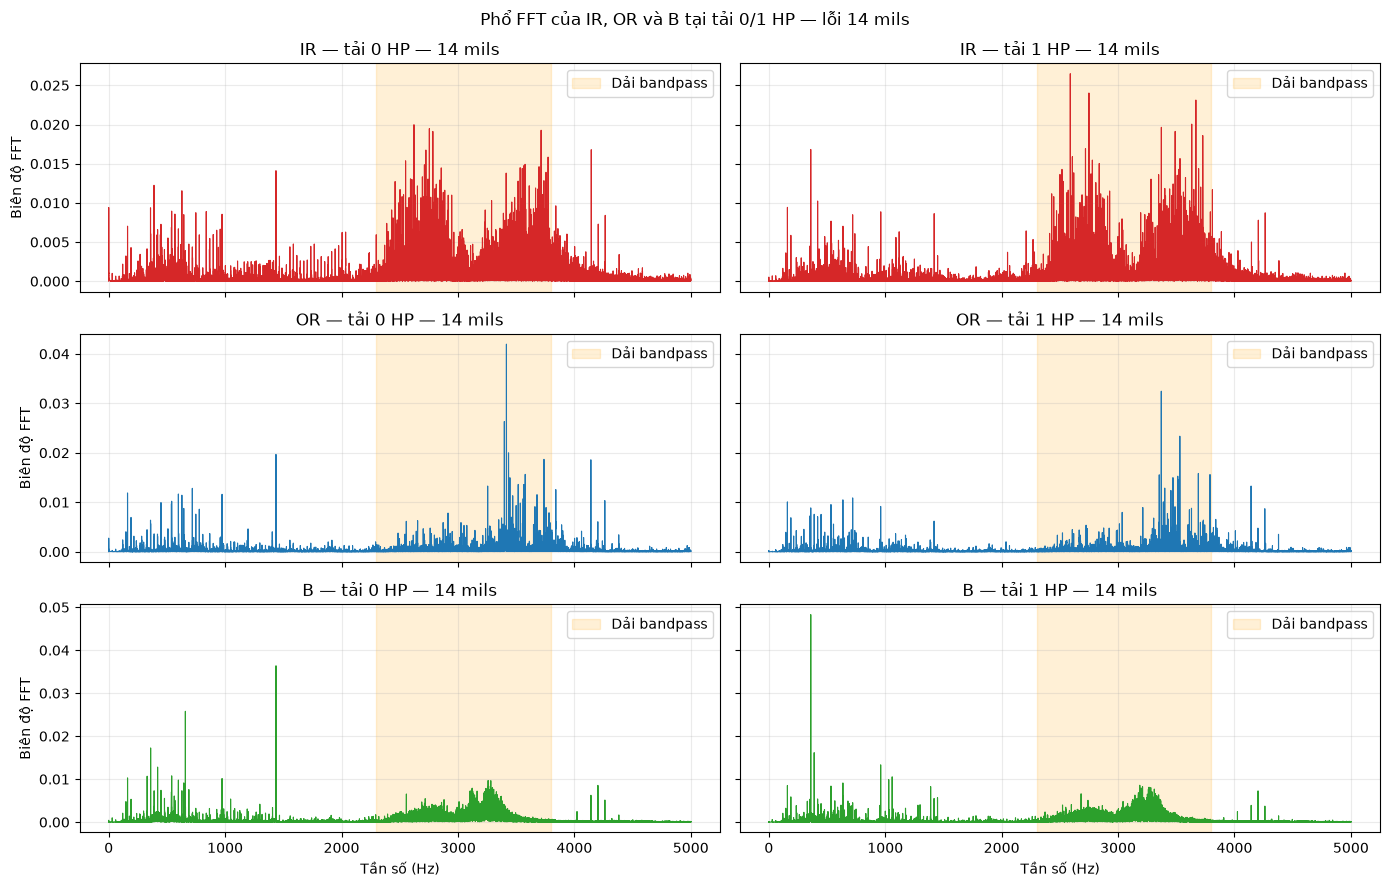

In [3]:
FAULT_LABELS = ["IR", "OR", "B"]
LOADS_TO_PLOT = [0, 1]
DIAMETER_MILS = 14
FREQ_MAX_HZ = 5000

fault_colors = {"IR": "tab:red", "OR": "tab:blue", "B": "tab:green"}
fig, axes = plt.subplots(
    len(FAULT_LABELS), len(LOADS_TO_PLOT),
    figsize=(14, 9), sharex=True, sharey="row",
)

for row_idx, label in enumerate(FAULT_LABELS):
    for col_idx, load_hp in enumerate(LOADS_TO_PLOT):
        ax = axes[row_idx, col_idx]
        file_path = pick_file(
            manifest,
            label=label,
            load_hp=load_hp,
            diameter_mils=DIAMETER_MILS,
        )
        manifest_row = manifest.loc[manifest["file_path"] == file_path].iloc[0]
        fs = float(manifest_row["resolved_sample_rate_hz"])
        signal = io_utils.load_de_signal(Path(file_path))
        freqs, magnitude = dsp.compute_fft(signal - signal.mean(), fs)
        mask = freqs <= FREQ_MAX_HZ

        ax.plot(freqs[mask], magnitude[mask], color=fault_colors[label], linewidth=0.8)
        ax.axvspan(*BAND_HZ, alpha=0.16, color="orange", label="Dải bandpass")
        ax.set_title(f"{label} — tải {load_hp} HP — {DIAMETER_MILS} mils")
        ax.grid(alpha=0.25)
        ax.legend(loc="upper right")
        print(f"{label} | {load_hp} HP | {DIAMETER_MILS} mils: {Path(file_path).name}")

    axes[row_idx, 0].set_ylabel("Biên độ FFT")

for ax in axes[-1, :]:
    ax.set_xlabel("Tần số (Hz)")

fig.suptitle("Phổ FFT của IR, OR và B tại tải 0/1 HP — lỗi 14 mils")
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "03_choose_bandpass_fft_loads0_1_014mils.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

IR | 1 HP | 14 mils: 170_1.mat | order mục tiêu BPFI=5.4152
OR | 1 HP | 14 mils: 198@6_1.mat | order mục tiêu BPFO=3.5848
B | 1 HP | 14 mils: 186_1.mat | order mục tiêu BSF=2.3567


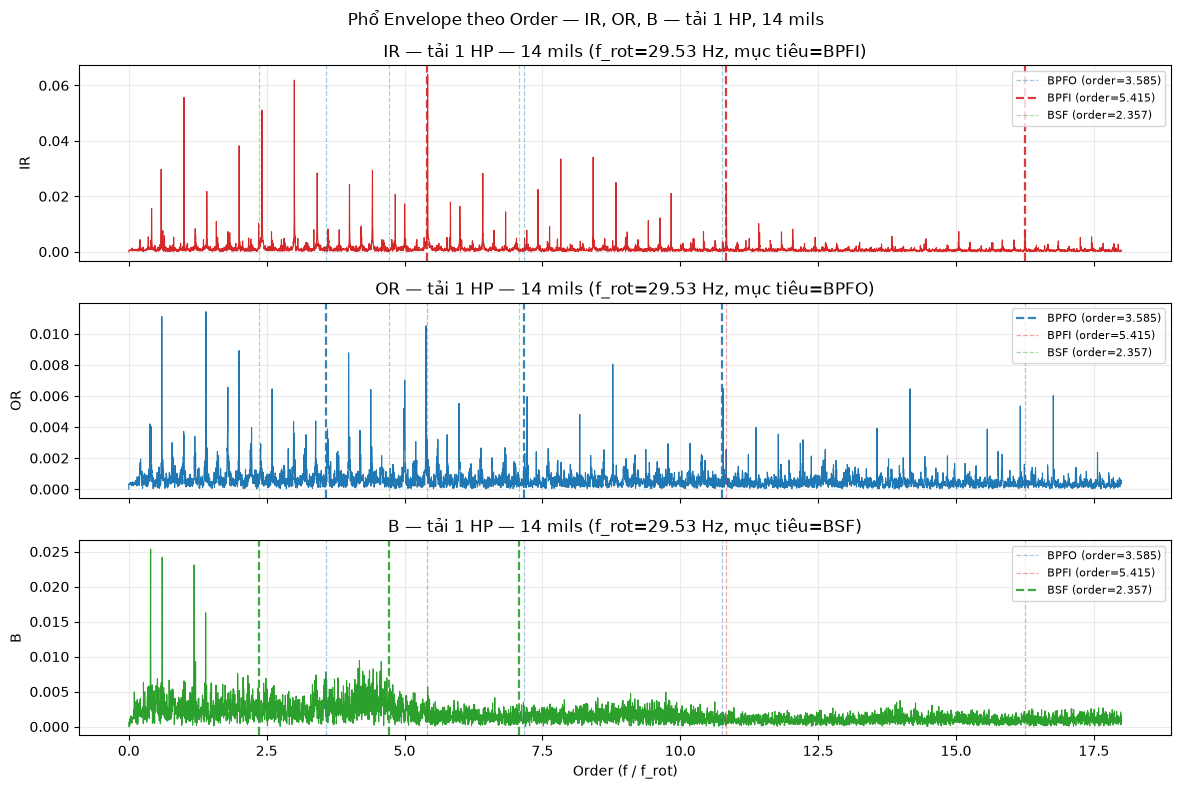

In [4]:
# ===== Order & Order Normalization — tải 1 HP, 14 mils =====
LOAD_HP_ORDER = 1
DIAMETER_MILS_ORDER = 14
ORDER_MAX = 18          # đủ tới BPFI h3 (order 16.25), khớp xlim 500Hz cũ ở f_rot~29.5Hz
FAULT_KEY_BY_LABEL = {"IR": "BPFI", "OR": "BPFO", "B": "BSF"}
ORDER_COLOR = {"BPFO": "tab:blue", "BPFI": "tab:red", "BSF": "tab:green"}

rpm_order = cfg.NOMINAL_RPM_BY_LOAD[LOAD_HP_ORDER]
f_rot_order = rpm_order / 60.0
fault_orders = {k: v / f_rot_order for k, v in cfg.bearing_fault_frequencies(rpm_order).items()}

fig, axes = plt.subplots(len(FAULT_LABELS), 1, figsize=(12, 8), sharex=True)
axes = np.atleast_1d(axes)

for ax, label in zip(axes, FAULT_LABELS):
    file_path = pick_file(
        manifest, label=label, load_hp=LOAD_HP_ORDER, diameter_mils=DIAMETER_MILS_ORDER,
    )
    manifest_row = manifest.loc[manifest["file_path"] == file_path].iloc[0]
    fs = float(manifest_row["resolved_sample_rate_hz"])
    signal = io_utils.load_de_signal(Path(file_path))

    # Phổ ĐƯỜNG BAO: tần số lỗi là hiện tượng ĐIỀU BIÊN của dải cộng hưởng,
    # chỉ hiện rõ sau khi giải điều chế — không thấy trực tiếp trên phổ thô.
    env = dsp.hybrid_envelope(signal, fs, band=BAND_HZ, lp_cutoff=LP_CUTOFF_HZ)
    freqs, magnitude = dsp.compute_fft(env - env.mean(), fs)
    orders = freqs / f_rot_order
    mask = orders <= ORDER_MAX

    target_key = FAULT_KEY_BY_LABEL[label]
    ax.plot(orders[mask], magnitude[mask], color=fault_colors[label], linewidth=0.8)
    for key, order_val in fault_orders.items():
        if key not in ORDER_COLOR:
            continue
        is_target = key == target_key
        for h in (1, 2, 3):
            ax.axvline(order_val * h, color=ORDER_COLOR[key],
                      linestyle="--" if is_target else "--",
                      linewidth=1.6 if is_target else 0.9,
                      alpha=0.9 if is_target else 0.4,
                      label=f"{key} (order={order_val:.3f})" if h == 1 else None)
    ax.set_ylabel(label)
    ax.set_title(f"{label} — tải {LOAD_HP_ORDER} HP — {DIAMETER_MILS_ORDER} mils "
               f"(f_rot={f_rot_order:.2f} Hz, mục tiêu={target_key})")
    ax.grid(alpha=0.25)
    ax.legend(loc="upper right", fontsize=8)
    print(f"{label} | {LOAD_HP_ORDER} HP | {DIAMETER_MILS_ORDER} mils: {Path(file_path).name} "
         f"| order mục tiêu {target_key}={fault_orders[target_key]:.4f}")

axes[-1].set_xlabel("Order (f / f_rot)")
fig.suptitle(f"Phổ Envelope theo Order — IR, OR, B — tải {LOAD_HP_ORDER} HP, "
            f"{DIAMETER_MILS_ORDER} mils")
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / f"03_order_spectrum_load{LOAD_HP_ORDER}_{DIAMETER_MILS_ORDER:03d}mils.png",
    dpi=150, bbox_inches="tight",
)
plt.show()

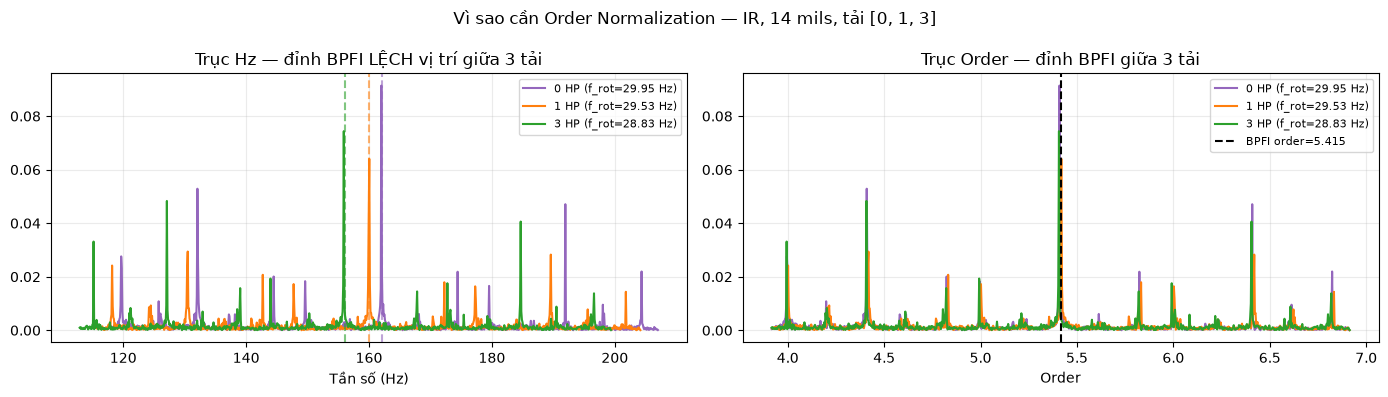

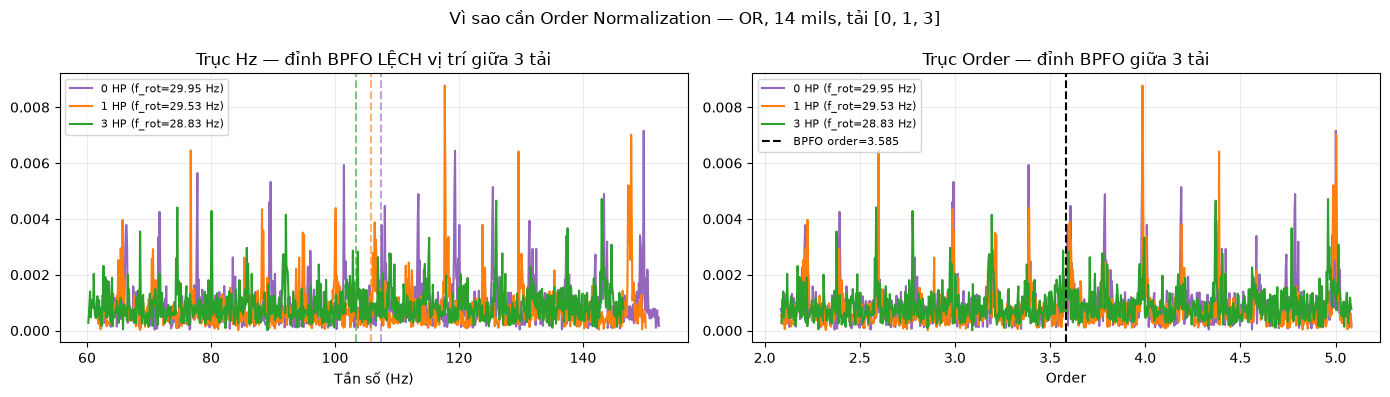

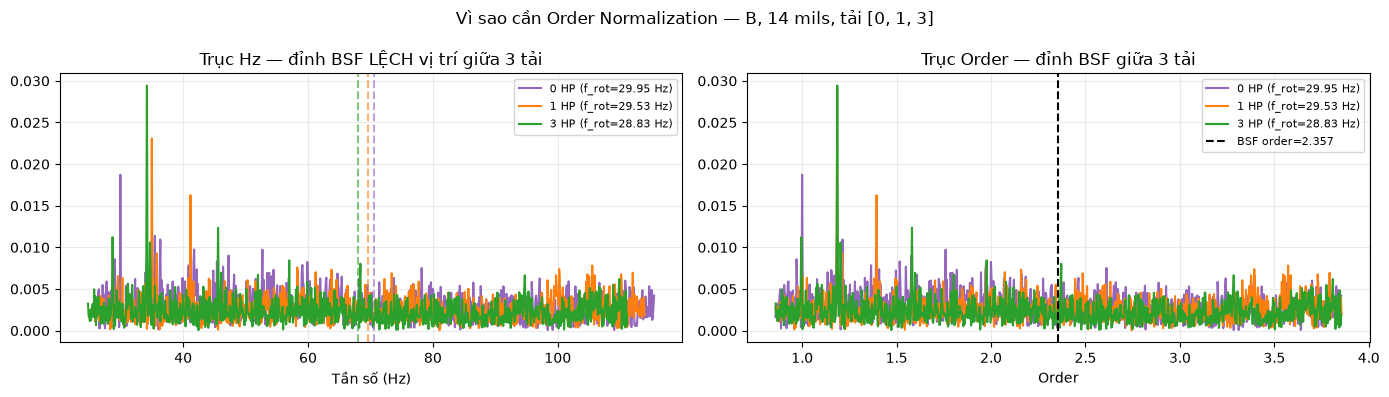

In [5]:
# ===== So sánh 3 tải để thấy lợi ích của Order Normalization — IR, OR, B =====
LOADS_COMPARE = [0, 1, 3]
DIAMETER_COMPARE = 14
FAULT_LABELS_COMPARE = ["IR", "OR", "B"]
ZOOM_MARGIN_ORDER = 1.5     # nới rộng quanh order mục tiêu để thấy cả sideband lân cận
LOAD_COLORS = ["tab:purple", "tab:orange", "tab:green"]   # phải cùng độ dài với LOADS_COMPARE

for LABEL_COMPARE in FAULT_LABELS_COMPARE:
    target_key = FAULT_KEY_BY_LABEL[LABEL_COMPARE]

    fig, (ax_hz, ax_ord) = plt.subplots(1, 2, figsize=(14, 4))
    for load_hp, color in zip(LOADS_COMPARE, LOAD_COLORS):
        file_path = pick_file(manifest, label=LABEL_COMPARE, load_hp=load_hp,
                              diameter_mils=DIAMETER_COMPARE)
        row = manifest.loc[manifest["file_path"] == file_path].iloc[0]
        fs = float(row["resolved_sample_rate_hz"])
        signal = io_utils.load_de_signal(Path(file_path))
        env = dsp.hybrid_envelope(signal, fs, band=BAND_HZ, lp_cutoff=LP_CUTOFF_HZ)
        freqs, magnitude = dsp.compute_fft(env - env.mean(), fs)

        f_rot = cfg.NOMINAL_RPM_BY_LOAD[load_hp] / 60.0
        f_target = cfg.bearing_fault_frequencies(cfg.NOMINAL_RPM_BY_LOAD[load_hp])[target_key]
        o_target = f_target / f_rot          # order của tần số lỗi ở tải này
        lbl = f"{load_hp} HP (f_rot={f_rot:.2f} Hz)"

        # Cửa sổ zoom Hz tính theo order margin * f_rot của TỪNG tải,
        # vì cùng 1 order margin ứng với số Hz khác nhau khi RPM khác nhau
        mask_hz = (freqs >= f_target - ZOOM_MARGIN_ORDER * f_rot) & \
                  (freqs <= f_target + ZOOM_MARGIN_ORDER * f_rot)
        ax_hz.plot(freqs[mask_hz], magnitude[mask_hz], color=color, label=lbl)
        ax_hz.axvline(f_target, color=color, linestyle="--", alpha=0.6)

        orders = freqs / f_rot
        mask_ord = (orders >= o_target - ZOOM_MARGIN_ORDER) & \
                   (orders <= o_target + ZOOM_MARGIN_ORDER)
        ax_ord.plot(orders[mask_ord], magnitude[mask_ord], color=color, label=lbl)

    # Order lý thuyết không đổi theo tải -> lấy 1 lần từ bảng chung
    o_theory = fault_orders[target_key]
    ax_hz.set_title(f"Trục Hz — đỉnh {target_key} LỆCH vị trí giữa {len(LOADS_COMPARE)} tải")
    ax_hz.set_xlabel("Tần số (Hz)")
    ax_hz.legend(fontsize=8)
    ax_hz.grid(alpha=0.25)

    ax_ord.axvline(o_theory, color="black", linestyle="--",
                   label=f"{target_key} order={o_theory:.3f}")
    ax_ord.set_title(f"Trục Order — đỉnh {target_key} giữa {len(LOADS_COMPARE)} tải")
    ax_ord.set_xlabel("Order")
    ax_ord.legend(fontsize=8)
    ax_ord.grid(alpha=0.25)

    fig.suptitle(f"Vì sao cần Order Normalization — {LABEL_COMPARE}, {DIAMETER_COMPARE} mils, "
                 f"tải {LOADS_COMPARE}")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"03_order_normalization_benefit_{LABEL_COMPARE}.png",
                dpi=150, bbox_inches="tight")
    plt.show()